# Fishing vessel AIS disabling analysis
After the paper 'Hot spots of unseen fishing vessels' (Welch et al.) this project aims to apply boosted regression trees to identify the primary drivers of suspected AIS disabling. The findings of two periods of times are compared (2017-2019 and 2023-2025)

In [6]:
import pandas as pd
import ast

In [3]:
df_a = pd.read_csv("data/raw/gaps_2017_2019.csv")
df_a

,start,end,id,type,position,regions,bounding_box,distances,vessel,encounter,fishing,gap,loitering,port_visit
0,2017-01-21 09:20:04+00:00,2017-01-22 16:56:57+00:00,3bdc90a2712347db50d6b6ba99eecdc0,gap,"{'lat': 31.0785, 'lon': -170.837}","{'mpa': [], 'eez': [], 'rfmo': ['ACAP', 'NPFC'...","[-171.185185, 30.9829966667, -170.489515, 31.1...","{'start_distance_from_shore_km': 588.0, 'end_d...",{'id': '1147e3e02-2c03-56f8-0885-3643c0896772'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN
1,2017-01-09 02:58:25+00:00,2017-01-09 18:38:08+00:00,704bd86272cd43eba5bcb9d5343908cd,gap,"{'lat': 4.9303, 'lon': -18.4853}","{'mpa': [], 'eez': [], 'rfmo': ['ICCAT', 'ACAP...","[-18.800448333333332, 4.846435, -18.1701916667...","{'start_distance_from_shore_km': 698.0, 'end_d...",{'id': '13bf6bd39-9459-33e7-83ef-aacbe803d029'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN
2,2017-01-28 00:11:49+00:00,2017-01-28 16:30:40+00:00,31a325ef26e6d7958b403e35c87da6cb,gap,"{'lat': 56.2954, 'lon': -167.3866}","{'mpa': [], 'eez': ['8463'], 'rfmo': ['ACAP', ...","[-167.5417933333, 56.2650366667, -167.231555, ...","{'start_distance_from_shore_km': 123.0, 'end_d...",{'id': '1d64fc20f-f64a-b17f-bbbc-6cb9475eb37e'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN
3,2017-01-11 21:13:05+00:00,2017-01-12 16:21:25+00:00,33bb0b2710a5a5651ae6ac59ff2cb95a,gap,"{'lat': 56.2089, 'lon': -167.3621}","{'mpa': [], 'eez': ['8463'], 'rfmo': ['ACAP', ...","[-167.4774566667, 56.11081, -167.2472516666666...","{'start_distance_from_shore_km': 127.0, 'end_d...",{'id': '1d64fc20f-f64a-b17f-bbbc-6cb9475eb37e'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN
4,2017-01-06 06:10:41+00:00,2017-01-07 03:30:15+00:00,2aae28fc35e79ca04e700b5a6d3adefe,gap,"{'lat': -45.6804, 'lon': -60.5852}","{'mpa': [], 'eez': [], 'rfmo': ['ICCAT', 'IWC'...","[-60.6501483333, -45.6912383333, -60.520263333...","{'start_distance_from_shore_km': 397.0, 'end_d...",{'id': '23c02e9d9-904d-2b0f-50bb-fbbb023c843c'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64224,2019-12-24 11:21:49+00:00,2020-05-11 20:29:57+00:00,ef74d1fe32fb2cf2aa94bc2b0412a57c,gap,"{'lat': 23.7094, 'lon': 179.6589}","{'mpa': [], 'eez': [], 'rfmo': ['ACAP', 'WCPFC...","[179.40094, 10.9682833333, 179.97366166666666,...","{'start_distance_from_shore_km': 925.0, 'end_d...",{'id': '22bd2e044-4257-421d-7f68-85d8c86af475'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN
64225,2019-12-22 05:33:16+00:00,2020-05-16 13:25:53+00:00,fed315d1e0e7267576e53aac99e82bbb,gap,"{'lat': 17.2432, 'lon': 63.3783}","{'mpa': [], 'eez': [], 'rfmo': ['ACAP', 'IOTC'...","[62.6825066667, 15.8240833333, 64.0634733333, ...","{'start_distance_from_shore_km': 442.0, 'end_d...",{'id': '746191123-3ef3-c8ef-eea6-692632cef2f3'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN
64226,2019-12-28 11:15:19+00:00,2020-06-14 04:37:07+00:00,44733e8c26042113076fa6f84ba5f5c0,gap,"{'lat': 10.2268, 'lon': 83.772}","{'mpa': [], 'eez': [], 'rfmo': ['ACAP', 'IOTC'...","[65.19016, 2.4871633333, 101.5347666667, 16.96...","{'start_distance_from_shore_km': 690.0, 'end_d...",{'id': '0e15cf51d-d5fe-1c29-e286-d737550cb351'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN
64227,2019-12-29 02:19:59+00:00,2020-06-04 05:54:02+00:00,3268e989071efdc4fd88578da356bf19,gap,"{'lat': 13.2733, 'lon': 68.3031}","{'mpa': [], 'eez': [], 'rfmo': ['ACAP', 'IOTC'...","[65.22096, 9.211475, 71.28426666666667, 17.299...","{'start_distance_from_shore_km': 663.0, 'end_d...",{'id': 'dccb952b9-9645-9deb-e00d-36212a18b0de'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN


In [ ]:
df_b = pd.read_csv("data/raw/gaps_2023_2025.csv")
df_b
import pprint
pprint.pprint(df_b.iloc[0]['gap']) # off position for linear interpolation later

("{'intentional_disabling': True, 'distance_km': '5567.810777813008', "
 "'duration_hours': 30539.083333333332, 'implied_speed_knots': "
 "'0.09844360018995019', 'positions_12_hours_before_sat': '41', "
 "'positions_per_day_sat_reception': 148.9185135079054, 'off_position': "
 "{'lat': -0.27502333333333334, 'lon': 77.50208833333333}, 'on_position': "
 "{'lat': 25.01511, 'lon': 122.226193}}")


## Step 1: Data Filtering

In [7]:
df_b = pd.read_csv("data/gaps_2023_2025.csv")
df_b['start'] = pd.to_datetime(df_b['start'], utc=True)
df_b['end'] = pd.to_datetime(df_b['end'], utc=True)

df_b['duration_hours'] = (df_b['end'] - df_b['start']).dt.total_seconds() / 3600
df_b['distances'] = df_b['distances'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
df_b['start_distance_from_shore_km'] = df_b['distances'].apply(lambda x: x.get('start_distance_from_shore_km'))

df_b = df_b[
    (df_b['duration_hours'] >= 12) &
    (df_b['duration_hours'] <= 336) &
    (df_b['start_distance_from_shore_km'] > 92.6)
]

print(f"After filtering: {len(df_b)} events")
print(df_b['duration_hours'].describe())

After filtering: 62887 events
count    62887.000000
mean        54.117811
std         65.862311
min         12.000000
25%         15.380556
50%         24.237500
75%         60.261944
max        335.951944
Name: duration_hours, dtype: float64


In [8]:
vessel_info_b = pd.read_csv("data/raw/vessel_info_2023_2025.csv")

vessel_info_b  

,vessel_id,gear_types,ship_types
0,652777bae-e8cb-8c7a-0087-b901713508e9,"[{'name': 'SQUID_JIGGER', 'source': 'COMBINATI...","[{'name': 'FISHING', 'source': 'COMBINATION_OF..."
1,dc46c05b1-14cb-3982-c7ba-006177f31c4e,"[{'name': 'SQUID_JIGGER', 'source': 'COMBINATI...","[{'name': 'FISHING', 'source': 'COMBINATION_OF..."
2,846033143-3b0e-280b-4192-5b20038de591,"[{'name': 'SET_GILLNETS', 'source': 'COMBINATI...","[{'name': 'FISHING', 'source': 'COMBINATION_OF..."
3,702326977-73e5-9814-e08a-d1d868b3d51e,"[{'name': 'TUNA_PURSE_SEINES', 'source': 'COMB...","[{'name': 'FISHING', 'source': 'COMBINATION_OF..."
4,79f936b24-41b4-051b-f0ca-4b605107e733,"[{'name': 'DRIFTING_LONGLINES', 'source': 'COM...","[{'name': 'FISHING', 'source': 'COMBINATION_OF..."
...,...,...,...
21216,92c52191f-f24c-a411-1116-63327db31538,"[{'name': 'DRIFTING_LONGLINES', 'source': 'COM...","[{'name': 'FISHING', 'source': 'COMBINATION_OF..."
21217,1aba618f0-0586-6513-341f-b28e30fb59a2,"[{'name': 'DRIFTING_LONGLINES', 'source': 'COM...","[{'name': 'FISHING', 'source': 'COMBINATION_OF..."
21218,917e9d030-0f11-f89e-47a3-60281655e361,"[{'name': 'POLE_AND_LINE', 'source': 'COMBINAT...","[{'name': 'FISHING', 'source': 'COMBINATION_OF..."
21219,d66959f7b-b5c5-bc90-e400-679858ee71c3,"[{'name': 'INCONCLUSIVE', 'source': 'COMBINATI...","[{'name': 'FISHING', 'source': 'COMBINATION_OF..."


## Step 2: Spatial Allocation

## Step 3: Create Loitering Activity Raster

In [10]:

import numpy as np

df_loitering = pd.read_csv('data/raw/loitering_2023_2025.csv')

# Extract lat/lon from position column
df_loitering['position'] = df_loitering['position'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
df_loitering['lat'] = df_loitering['position'].apply(lambda x: x['lat'])
df_loitering['lon'] = df_loitering['position'].apply(lambda x: x['lon'])

# Extract duration in hours from loitering column
df_loitering['loitering'] = df_loitering['loitering'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
df_loitering['duration_hours'] = df_loitering['loitering'].apply(lambda x: x.get('total_time_hours', 0))

# Snap to quarter degree grid
df_loitering['lat_grid'] = np.floor(df_loitering['lat'] / 0.25) * 0.25
df_loitering['lon_grid'] = np.floor(df_loitering['lon'] / 0.25) * 0.25

# Sum loitering hours per grid cell
loitering_grid = df_loitering.groupby(['lat_grid', 'lon_grid'])['duration_hours'].sum().reset_index()
loitering_grid.columns = ['lat', 'lon', 'loitering_hours']

# Log transform to remove left skew (add 1 to avoid log(0))
loitering_grid['loitering_hours_log'] = np.log1p(loitering_grid['loitering_hours'])

print(loitering_grid.describe())
loitering_grid.to_csv("data/loitering_grid.csv", index=False)

                lat           lon  loitering_hours  loitering_hours_log
count  26667.000000  26667.000000     26667.000000         26667.000000
mean      10.985122     34.592493        47.582490             2.917514
std       30.598512    105.366660       170.253016             1.301182
min      -63.250000   -180.000000         1.000000             0.693147
25%       -8.500000    -58.750000         6.002639             1.946287
50%        2.250000     57.500000        16.003611             2.833426
75%       37.750000    137.500000        43.121806             3.786954
max       87.000000    179.750000     14263.055833             9.565498


Matplotlib is building the font cache; this may take a moment.
/home/yolanda/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
/home/yolanda/.local/lib/python3.12/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/home/yolanda/.local/lib/python3.12/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


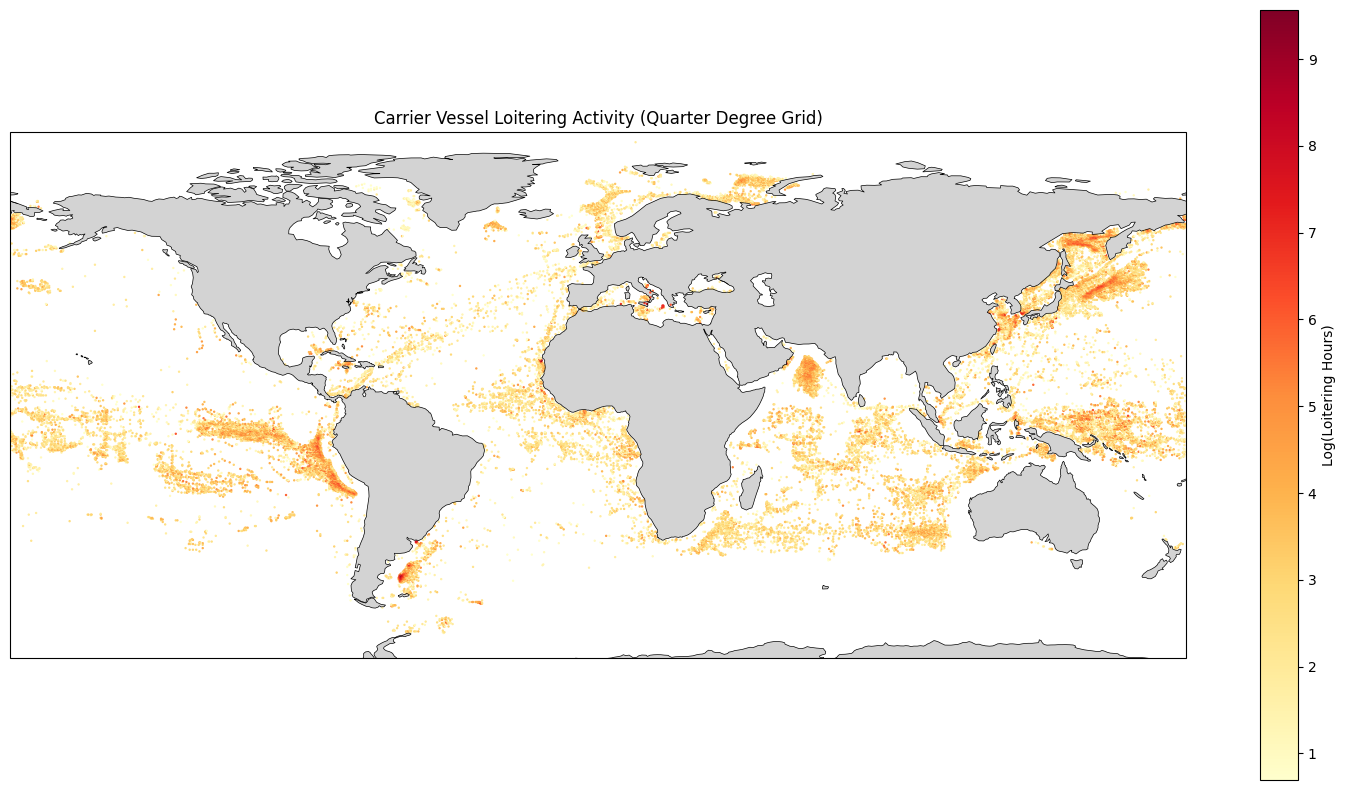

In [2]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

loitering_grid = pd.read_csv("data/loitering_grid.csv")

fig, ax = plt.subplots(figsize=(15, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
scatter = ax.scatter(
    loitering_grid['lon'],
    loitering_grid['lat'],
    c=loitering_grid['loitering_hours_log'],
    cmap='YlOrRd',
    s=0.5,
    transform=ccrs.PlateCarree()
)
plt.colorbar(scatter, ax=ax, label='Log(Loitering Hours)')
ax.set_title('Carrier Vessel Loitering Activity (Quarter Degree Grid)')
plt.tight_layout()
plt.savefig('loitering_grid.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
pip install --upgrade matplotlib cartopy --break-system-packages

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 253.9 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 2.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 4.1 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.
